# Constraint Satisfaction Problem : Graph coloring


## Create Data

We can create a planar graph with $n$ vertices by randomly placing $n$ points in 2-dimensional Euclidean space and then performing a [Delaunay triangulation](https://en.wikipedia.org/wiki/Delaunay_triangulation).

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


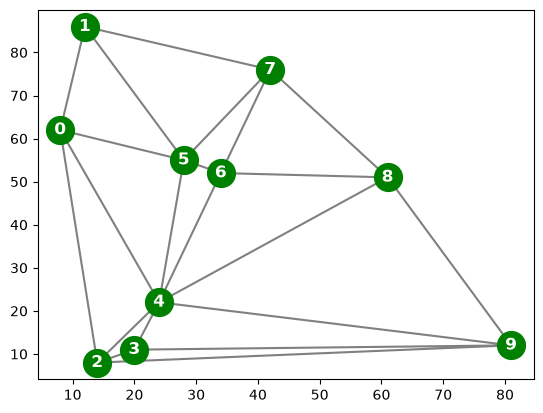

In [5]:
import numpy as np
import matplotlib.pyplot as plt
%pip install scipy
from scipy.spatial import Delaunay

np.random.seed(1111)

# create points and sort them by 
n = 10
points = np.random.randint(100, size=(n, 2))
o = np.argsort(points[:,0])
points = points[o,:]


# triangulate
tri = Delaunay(points)


# plot
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")
plt.plot(points[:,0], points[:,1], 'o', color = "green", markersize = 20)

for i in range(len(points)):
       plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

The triangulation can be converted into a list with an array of neighbor vertex indices for each point (see man page for [scipy.spatial.Delaunay](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Delaunay.html)). 

In [6]:
(indptr, indices) = tri.vertex_neighbor_vertices

neighbors = []

for k in range(len(indptr)-1):
    neighbors.append(np.sort(indices[indptr[k]:indptr[k+1]]))
    
neighbors

[array([1, 2, 4, 5], dtype=int32),
 array([0, 5, 7], dtype=int32),
 array([0, 3, 4, 9], dtype=int32),
 array([2, 4, 9], dtype=int32),
 array([0, 2, 3, 5, 6, 8, 9], dtype=int32),
 array([0, 1, 4, 6, 7], dtype=int32),
 array([4, 5, 7, 8], dtype=int32),
 array([1, 5, 6, 8], dtype=int32),
 array([4, 6, 7, 9], dtype=int32),
 array([2, 3, 4, 8], dtype=int32)]

The first row are the indices for the points neighboring point 0.

## Define CSP

The problem is defined as a dictionary with variable names, a dictionary with domain values for each variable and a set of binary  not-equal constraints (tuples of variables that are not allowed to have the same value).  

In [8]:
variables = [str(var) for var in range(n)]

#domain = ['red', 'blue', 'green', 'orange']
domain = ['red', 'blue', 'green']
domains = {}
for v in variables: 
    domains[v] = domain

# create binary constraints
constraints = {}
for i in range(len(neighbors)):
    for j in neighbors[i]:
        if(i<j): constraints[tuple([str(i), str(j)])] = True
constraints = constraints.keys()

csp = {'variables': variables, 'domains': domains, 'constraints': constraints, }
csp

{'variables': ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'],
 'domains': {'0': ['red', 'blue', 'green'],
  '1': ['red', 'blue', 'green'],
  '2': ['red', 'blue', 'green'],
  '3': ['red', 'blue', 'green'],
  '4': ['red', 'blue', 'green'],
  '5': ['red', 'blue', 'green'],
  '6': ['red', 'blue', 'green'],
  '7': ['red', 'blue', 'green'],
  '8': ['red', 'blue', 'green'],
  '9': ['red', 'blue', 'green']},
 'constraints': dict_keys([('0', '1'), ('0', '2'), ('0', '4'), ('0', '5'), ('1', '5'), ('1', '7'), ('2', '3'), ('2', '4'), ('2', '9'), ('3', '4'), ('3', '9'), ('4', '5'), ('4', '6'), ('4', '8'), ('4', '9'), ('5', '6'), ('5', '7'), ('6', '7'), ('6', '8'), ('7', '8'), ('8', '9')])}

## Check Completeness and Consistency

`assignment` is a dictionary. Assigned variables have an entry with the variable name as the key. `{}` is therefore the empty assignment.

In [9]:
def complete(assignment, csp):
    return(all([v in assignment.keys() for v in csp['variables']])) 

print("complete({}, csp) =", complete({}, csp))

print("complete({...complete list...}, csp) =", 
      complete({'0': 'red', '1': 'red', '2': 'red', '3': 'red', '4': 'red', 
          '5': 'red', '6': 'red', '7': 'red', '8': 'red', '9': 'red'}, csp))

complete({}, csp) = False
complete({...complete list...}, csp) = True


In [11]:
def consistent(assignment, csp):
    for constr in csp['constraints']:
        if(constr[0] in assignment.keys() and constr[1] in assignment.keys()):
            if assignment[constr[0]] == assignment[constr[1]]: return(False)
        
    return(True)
        
print("consistent({}, csp) =", consistent({}, csp))
print("consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) =", 
      consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp))

consistent({}, csp) = True
consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) = False


## Implement Simple Backtracking Search

In [12]:
# TODO: implement variable ordering. Choose variable with the minimum-remaining-values (MRV)
def select_unassigned_var(assignment, csp):
    if(complete(assignment, csp)): return(None)
    
    return(csp['variables'][np.where([not v in assignment.keys() for v in csp['variables']])[0][0]])

print("select_unassigned_var({'0': 'red', '1': 'blue'}, csp) =", 
     select_unassigned_var({'0': 'red', '1': 'blue'}, csp))

select_unassigned_var({'0': 'red', '1': 'blue'}, csp) = 2


In [ ]:
# I use a global variable to turn on verbose mode in the recursion
#VERBOSE = True
VERBOSE = False
COUNT = 0

# returns None for failure
def backtrack_search(csp):
    global COUNT
    COUNT = 0
    
    assignment = backtrack({}, csp)
    
    print(f"Checked nodes: {COUNT}")
    
    return assignment

def backtrack(assignment, csp):
    global VERBOSE, COUNT
    
    COUNT += 1
    
    if complete(assignment, csp): 
        return assignment
    
    var = select_unassigned_var(assignment, csp)
    
    # TODO: implement value ordering. Use the least-constraining-value heuristic. 
    # for val in order_domain(assignment, var, csp)
    for val in csp['domains'][var]:
        assignment[var] = val
        
        if VERBOSE: print(f"Checking: {assignment}")
        
        if consistent(assignment, csp):
            
            #TODO: add inference for early failing (forward checking, )
            # if inference_fails(assignment, csp): return(None)
            result = backtrack(assignment, csp)
            if not result is None:
                    return(result)
                
        del assignment[var]
        
    if VERBOSE: print(f"Backtracking")
    return(None) 

## Run Backtracking Search on the Random Problem

In [14]:
%time res = backtrack_search(csp)
display(res)

Checked nodes: 70
CPU times: total: 0 ns
Wall time: 711 μs


None

Plot the resulting coloring

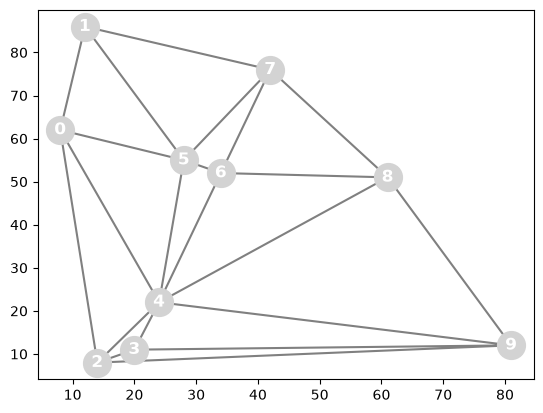

In [16]:
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")

for i in range(len(points)):
        if res is not None and str(i) in res:
            plt.plot(points[i, 0], points[i, 1], 'o', color=res[str(i)], markersize=20)
        else:
            plt.plot(points[i, 0], points[i, 1], 'o', color='lightgray', markersize=20)
        plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

## Assignment

Implement the following graph coloring algorithms:

* Add variable and value ordering to the implementation.
* Add forward checking to the implementation.
* Implement hill climbing local search with the min-conflicts heuristic.

Try to color graphs of several sizes with 3 and 4 colors. For each $n$, generate several random instances, and try to make n as large as you can manage. On average, how many constraints (edges) do your map coloring instances have for each $n$? Report the performance of each search algorithm as a function of $n$. For both variants of backtracking search, you can characterize performance in terms of the number of variable assignments attempted. For hill climbing search, report the number of uphill moves and random restarts required in order to reach a solution. Of course, you can also report raw running times as a function of $n$.

In [20]:
import random

# BÀI 3: Chọn biến theo Minimum Remaining Values (MRV)
def select_unassigned_var_mrv(assignment, csp):
    if len(assignment) == len(csp['variables']):
        return None
    # Danh sách các biến chưa được gán
    unassigned = [v for v in csp['variables'] if v not in assignment]
    
    def count_remaining_values(var):
        count = 0
        for val in csp['domains'][var]:
            assignment[var] = val
            if consistent(assignment, csp):
                count += 1
            del assignment[var]
        return count

    # Lựa chọn biến có miền giá trị hợp lệ còn lại nhỏ nhất
    return min(unassigned, key=count_remaining_values)

# BÀI 3: Thứ tự thử giá trị Least Constraining Value (LCV)
def order_domain_values_lcv(var, assignment, csp):
    def count_conflicts(val):
        conflicts = 0
        assignment[var] = val
        for u, v in csp['constraints']:
            # Đếm xem nếu gán màu này thì làm mất đi bao nhiêu cơ hội chọn màu của đỉnh kề chưa gán
            if u == var and v not in assignment and val in csp['domains'][v]: 
                conflicts += 1
            elif v == var and u not in assignment and val in csp['domains'][u]: 
                conflicts += 1
        del assignment[var]
        return conflicts
    
    return sorted(csp['domains'][var], key=count_conflicts)

# BÀI 4: Backtracking kết hợp Forward Checking
def backtrack_search_fc(csp):
    global COUNT
    COUNT = 0
    domains_copy = {v: list(csp['domains'][v]) for v in csp['variables']}
    return backtrack_fc({}, csp, domains_copy)

def backtrack_fc(assignment, csp, current_domains):
    global COUNT
    COUNT += 1
    
    if len(assignment) == len(csp['variables']): 
        return assignment
    
    var = select_unassigned_var_mrv(assignment, csp)
    
    for val in order_domain_values_lcv(var, assignment, csp):
        if val not in current_domains[var]:
            continue
            
        assignment[var] = val
        
        if consistent(assignment, csp):
            # Forward Checking: Thu hẹp miền giá trị của các láng giềng
            local_domains = {v: list(current_domains[v]) for v in csp['variables']}
            fc_failed = False
            for u, v in csp['constraints']:
                if u == var and v not in assignment and val in local_domains[v]:
                    local_domains[v].remove(val)
                    if not local_domains[v]: fc_failed = True # Rỗng miền -> Cắt tỉa (Pruning)
                elif v == var and u not in assignment and val in local_domains[u]:
                    local_domains[u].remove(val)
                    if not local_domains[u]: fc_failed = True
            
            if not fc_failed:
                result = backtrack_fc(assignment, csp, local_domains)
                if result is not None:
                    return result
                
        del assignment[var]
        
    return None

# BÀI 4: Thuật toán Min-Conflicts
def min_conflicts(csp, max_steps=1000):
    # Khởi tạo một phép gán đầy đủ nhưng ngẫu nhiên (chấp nhận có vi phạm)
    assignment = {v: random.choice(csp['domains'][v]) for v in csp['variables']}
    
    def get_conflicted_vars():
        conflicted = set()
        for u, v in csp['constraints']:
            if assignment[u] == assignment[v]:
                conflicted.add(u)
                conflicted.add(v)
        return list(conflicted)
    
    def count_local_conflicts(var, val):
        count = 0
        for u, v in csp['constraints']:
            if u == var and assignment[v] == val: count += 1
            elif v == var and assignment[u] == val: count += 1
        return count

    for i in range(max_steps):
        conflicted_vars = get_conflicted_vars()
        if not conflicted_vars:
            print(f"Hoàn thành Min-Conflicts trong {i} bước")
            return assignment
        
        # Chọn ngẫu nhiên một biến đang vi phạm
        var = random.choice(conflicted_vars)
        
        # Sửa sang giá trị giảm thiểu số xung đột nhất
        min_c = float('inf')
        best_vals = []
        for val in csp['domains'][var]:
            c = count_local_conflicts(var, val)
            if c < min_c:
                min_c = c
                best_vals = [val]
            elif c == min_c:
                best_vals.append(val)
                
        assignment[var] = random.choice(best_vals)
        
    print("Min-Conflicts vượt giới hạn lặp, không tìm được nghiệm.")
    return None